# The size and power of every test, measured on planted defects

**Question:** Does the study measure the size and the power of the engine's validation tests on planted defects of known truth, as the claim says, and what did the measurement find that a validator would not learn from the standard or the toolkits?

- **Level:** 4, proposed methods
- **Prerequisites:** notebooks 01 to 07 of this topic (the measurements, and the published literature they are set against)
- **Reading time:** about 60 minutes

## Objectives

By the end of this notebook you can:

- state the claim and the extent of the evidence behind it, counted over the eight families of case C22;
- measure live, with the engine's own studies, the size and the power of tests from families the credit notebooks do not cover;
- check every exact rejection probability against its simulated rate with the engine's rule `agrees`;
- replay one row of each family from its seed and see the same rate;
- list the defects in standard tests that the measurement found, with the number that evidences each, and say how far the claim reaches.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import os

# the bake fixes its thread counts (decision D16-18): BLAS sums a quadrature by thread
for _var in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[_var] = "4"

import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data are the eight families of case C22, validating the validator: `null`, `miscalibration`, `clustering`, `drift`, `discrimination-decay`, `leakage`, `broken-monotonicity` and `concentration`. Every dataset in them is drawn by a known-truth generator of `riskvalidation.generators` (licence MIT, class `generated`), so nothing here is real portfolio data and every number is a property of those generators and their assumptions.

- **Files read:** `data/derived/C22/<family>.json` for the eight families: `outputs.simulations` (each row a test, a severity, rates with errors, the exact probability where one exists, the seed), `outputs.panels` (whether a panel measures size or power), `outputs.generators` (configuration and truth), `findings` and `provenance`.
- **Not read:** `models-generators.json`, which describes the generators' models for the web, and `other-families.json`.

The next cell loads the eight files and prints the engine version that baked each beside the installed one.

In [2]:
# Load the eight families of case C22 and index their simulations
LANG = "en"
ROOT = Path("../../..").resolve()
names = ("null", "miscalibration", "clustering", "drift", "discrimination-decay", "leakage",
         "broken-monotonicity", "concentration")
families = {}
for n in names:
    path = ROOT / "data" / "derived" / "C22" / f"{n}.json"
    families[n] = json.loads(path.read_text(encoding="utf-8"))
rows = {n: {row["key"]: row for row in fam["outputs"]["simulations"]} for n, fam in families.items()}
for n in names:
    print(f"{n:22s} baked by riskvalidation {families[n]['provenance']['riskvalidation_version']}")
print("installed:", rv.__version__)

null                   baked by riskvalidation 1.0.1
miscalibration         baked by riskvalidation 1.0.1
clustering             baked by riskvalidation 1.0.1
drift                  baked by riskvalidation 1.0.1
discrimination-decay   baked by riskvalidation 1.0.1
leakage                baked by riskvalidation 1.0.1
broken-monotonicity    baked by riskvalidation 1.0.1
concentration          baked by riskvalidation 1.0.1
installed: 1.0.1


## Method

The performance of a test is measured as in Morris, White and Crowther (2019): a rejection rate is an estimate, reported with its Monte Carlo standard error $\sqrt{\hat r(1-\hat r)/n}$ and, here, the Wilson interval that Brown, Cai and DasGupta (2001) recommend. Size is the rate when the null holds and power the rate when a defect of known severity is present; each panel of a file says which of the two it measures. The steps use the engine's own functions, `simulate_study`, `Rate`, `agrees`, `simulate` and the generators, and add nothing to them.

## Comparison

What the standard, the literature and the tools offered a validator, from the research notebook 07 sets out:

- **The ECB's instructions (2019)** define the statistics and the p-values of the tests the engine implements and set no pass or fail thresholds, which are left to the institution. A validator who applies them must choose a threshold, and nothing in the instructions says how often the test will raise a false alarm or miss a defect.
- **BCBS Working Paper 14 (2005)** simulated two calibration tests and concluded that "at present no really powerful tests of adequate calibration are currently available".
- **Yurdakul and Naranjo (2020)** observed that the PSI bands of 0.10 and 0.25 are "used without reference to statistical type I or type II error rates", and measured them on one design.
- **Demler et al. (2012)** measured one test, DeLong on nested models, on one design.
- **The validation toolkits** the research surveyed list tests, thresholds and traffic lights, and recorded no measured size or power for any of them (UNVERIFIED beyond the documentation it read).

So the published literature measured a handful of tests, one design at a time, on the tests' own assumptions; nothing the research found measured every test of one engine under the same planted defects, with the Monte Carlo error of each rate.

## Evidence

**The measured size and power of the validation tests on planted defects.** For each test with a p-value, Contraste reports its rejection rate under its null at 5% and 1% and, for the tests with a planted defect to detect, its rejection rate against defects of known severity, each rate with its Monte Carlo standard error and Wilson interval, on generators whose truth is known. The claim is stated only as far as the committed files go, and the steps below measure that extent before anything is said about it:

1. the inventory of simulations, repetitions, tests and rates, and what each test was measured for;
2. a live measurement of size and power for tests of other families;
3. whether the exact probabilities agree with the simulated rates;
4. whether rows replay from their seeds;
5. what the measurement found in standard tests, and the register of findings.

### Step 1: the inventory

The next cell counts, over the eight files, the simulations, the repetitions, the distinct tests, the rates, the rows that carry an exact probability and the generators, and counts for each test its rows that measure size and its rows that measure power. A stacked bar per test draws the extent of the measurement.

simulations: 256 | repetitions: 651000
distinct tests: 42 | rates: 537 | exact rows: 47
generators with a written truth: 148
tests with a size row and no power row: 25


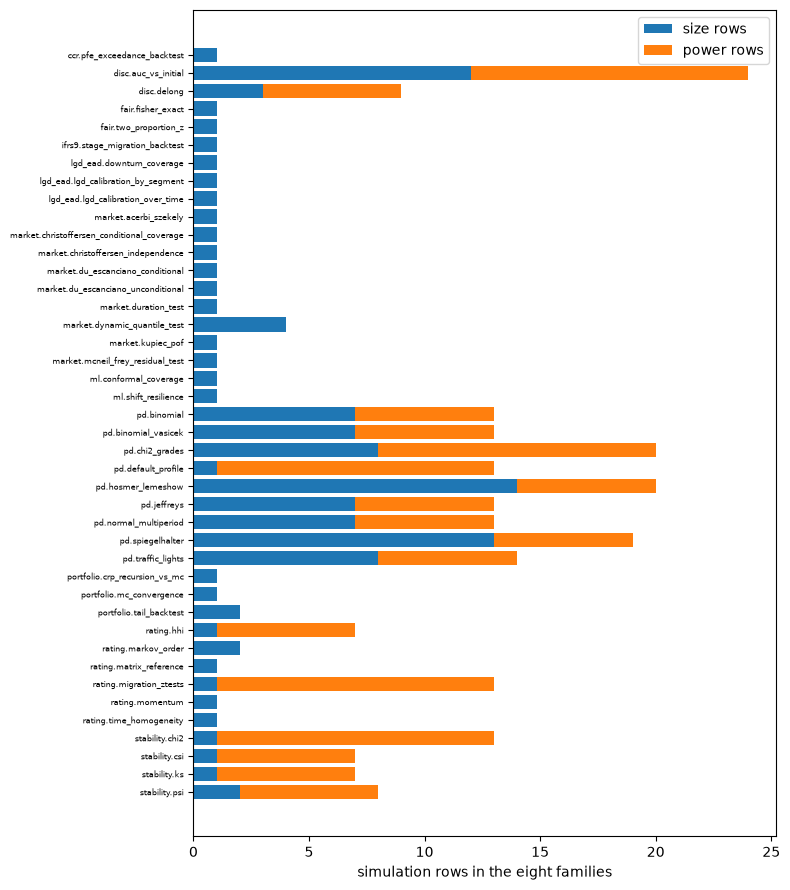

In [3]:
# Count simulations, repetitions, tests, rates and exact rows, and draw what was measured for each test
from collections import Counter

coverage = {}
rates = exact_rows = generators = 0
for n in names:
    measures = {p["id"]: p["measures"] for p in families[n]["outputs"]["panels"]}
    generators += len(families[n]["outputs"]["generators"])
    for s in rows[n].values():
        entry = coverage.setdefault(s["test_id"], Counter())
        entry[measures[s["panel"]]] += 1
        rates += len(s["rates"])
        exact_rows += s["exact"] is not None
total = sum(len(rows[n]) for n in names)
print("simulations:", total, "|", "repetitions:", sum(s["n_rep"] for n in names for s in rows[n].values()))
print("distinct tests:", len(coverage), "| rates:", rates, "| exact rows:", exact_rows)
print("generators with a written truth:", generators)
print("tests with a size row and no power row:", sum(1 for e in coverage.values() if e["power"] == 0))
tests = sorted(coverage)
fig, ax = plt.subplots(figsize=(8, 9))
size_rows = [coverage[t]["size"] for t in tests]
power_rows = [coverage[t]["power"] for t in tests]
ax.barh(range(len(tests)), size_rows, color="tab:blue", label="size rows")
ax.barh(range(len(tests)), power_rows, left=size_rows, color="tab:orange", label="power rows")
ax.set_yticks(range(len(tests)))
ax.set_yticklabels(tests, fontsize=6)
ax.invert_yaxis()
ax.set_xlabel("simulation rows in the eight families")
ax.legend()
fig.tight_layout()
plt.show()

The eight files hold 256 simulations and 651,000 seeded repetitions of 42 distinct tests, 537 rates in all, 47 rows with an exact probability and 148 generators with a written truth. The bars show that the measurement is wide but uneven: 25 tests have a size row and no power row, so the claim of power is narrower than the claim of size. The claim has to be read at that scale, which the Results restate, and not as "every test under every defect".

### Step 2: size and power measured live

The engine holds a named study for each registered test outside the credit families: a generator with the test's null true, one stated alternative, a seed and the rule. `study` returns it and `simulate_study` runs its null or its alternative. The next cell runs eight tests from market risk, fairness, portfolio credit, exposure, loss given default, IFRS 9 and machine learning, 400 repetitions each way, prints the size, the power and the stated alternative, and draws size and power for each.

market.kupiec_pof                    size 0.037 | power 0.660
market.christoffersen_independence   size 0.068 | power 0.840
fair.two_proportion_z                size 0.065 | power 0.983
portfolio.tail_backtest              size 0.033 | power 0.307
ccr.pfe_exceedance_backtest          size 0.043 | power 0.765
lgd_ead.downturn_coverage            size 0.050 | power 0.652
ifrs9.stage_migration_backtest       size 0.062 | power 0.728
ml.conformal_coverage                size 0.058 | power 1.000


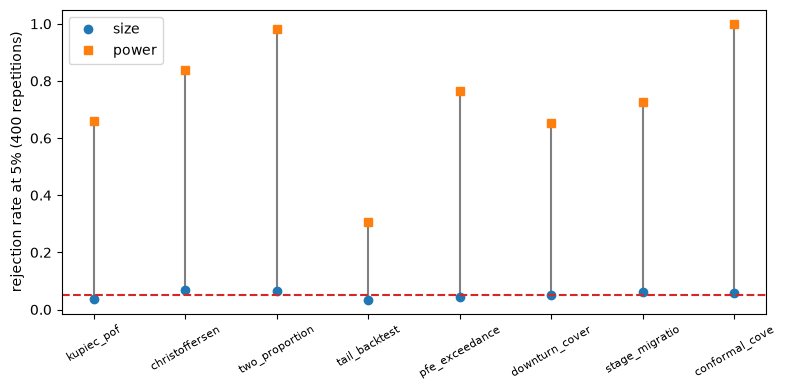

In [4]:
# Measure size and power live for eight tests of other families with the engine own studies
from riskvalidation.generators.size_studies import simulate_study, study

selected = ("market.kupiec_pof", "market.christoffersen_independence", "fair.two_proportion_z",
            "portfolio.tail_backtest", "ccr.pfe_exceedance_backtest", "lgd_ead.downturn_coverage",
            "ifrs9.stage_migration_backtest", "ml.conformal_coverage")
fig, ax = plt.subplots(figsize=(8, 4))
for position, test_id in enumerate(selected):
    item = study(test_id)
    null_run = simulate_study(item, "null", n_rep=400, seed=3)
    alt_run = simulate_study(item, "alternative", n_rep=400, seed=3)
    key = "p<0.05" if "p<0.05" in null_run.rates else next(iter(null_run.rates))
    size, power = null_run.rates[key], alt_run.rates[key]
    print(f"{test_id:36s} size {size.rate:.3f} | power {power.rate:.3f}")
    ax.plot([position, position], [size.rate, power.rate], color="gray")
    ax.plot(position, size.rate, "o", color="tab:blue", label="size" if position == 0 else None)
    ax.plot(position, power.rate, "s", color="tab:orange", label="power" if position == 0 else None)
ax.axhline(0.05, color="tab:red", linestyle="--")
ax.set_xticks(range(len(selected)))
ax.set_xticklabels([t.split(".")[1][:14] for t in selected], rotation=30, fontsize=8)
ax.set_ylabel("rejection rate at 5% (400 repetitions)")
ax.legend()
fig.tight_layout()
plt.show()

The sizes sit between 0.033 and 0.068, within the Monte Carlo error of 400 repetitions around 5%, and the powers range from 0.307 to 1.000. The portfolio tail backtest is the weak one, with 0.307 against its stated alternative, while the machine-learning coverage check and the fairness z-test reach 1.000 and 0.983. The figure makes one point: a test is not good or bad in the abstract, it has a size and a power against a stated defect, and those two numbers, which this study reports for each test, differ by a factor of three across families.

### Step 3: the exact probabilities and the simulated rates

For the count tests and the traffic lights over independent years the files carry the exact rejection probability beside the simulated rate. The next cell builds a `Rate` from the committed counts of every such row, applies the engine's `agrees` at both levels, prints the number of comparisons and agreements and the largest standardised gap, and draws the simulated rates against the exact ones.

comparisons (both levels): 94 | that agree: 94
largest standardised gap: 2.85


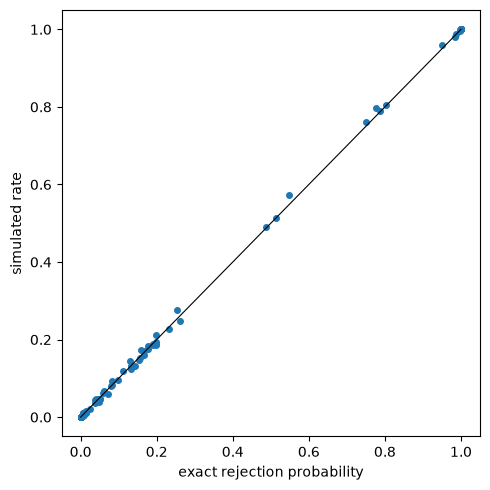

In [5]:
# Apply the agrees rule to every row that carries an exact probability, at both levels
from riskvalidation.harness.rates import Rate, agrees

compared = agreeing = 0
largest = 0.0
points = []
for n in names:
    for s in rows[n].values():
        for rule, exact in (s["exact"] or {}).items():
            c = s["rates"][rule]
            rate = Rate(c["rejections"], c["n"])
            compared += 1
            agreeing += agrees(rate, exact)
            points.append((exact, rate.rate))
            if 0.0 < exact < 1.0:
                largest = max(largest, abs(rate.rate - exact) / np.sqrt(exact * (1 - exact) / rate.n))
print("comparisons (both levels):", compared, "| that agree:", agreeing)
print("largest standardised gap:", round(float(largest), 2))
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([p[0] for p in points], [p[1] for p in points], "o", markersize=4)
ax.plot([0, 1], [0, 1], color="black", linewidth=0.8)
ax.set_xlabel("exact rejection probability")
ax.set_ylabel("simulated rate")
fig.tight_layout()
plt.show()

All 94 comparisons agree, and the largest standardised gap is 2.85, below the 3.29 criterion. The points lie on the diagonal from 0 to 1, including the extremes where the power is close to 1 and the tails are tight. For the rows with an exact value, the rate in the file is therefore not only reproducible: it is correct, since the binomial tail, a computation that draws no dataset, reaches it. That is the strongest check available, and it covers 47 rows.

### Step 4: rows replayed from their seeds

A rate that cannot be reproduced is not evidence. The next cell takes one row from each family, rebuilds its generator from the committed configuration with the engine's classes and runs `simulate` with the committed seed, the test and the number of repetitions, and prints the live rate beside the rate in the file.

In [6]:
# Replay one row of each family with its committed seed and print the live rate beside the committed one
from riskvalidation.generators.counts import DefaultCounts, feed_cell, feed_series
from riskvalidation.generators.drift import TwoSample
from riskvalidation.generators.ratings import GradeFrequencies, Migrations
from riskvalidation.generators.scores import BinormalScores, LogisticPortfolio
from riskvalidation.harness.run import simulate

classes = (DefaultCounts, TwoSample, GradeFrequencies, Migrations, BinormalScores, LogisticPortfolio)
CLASSES = {cls.name: cls for cls in classes}
replays = (("null", "pd.binomial@null", feed_cell()), ("miscalibration", "pd.traffic_lights@k1.5", feed_series()),
           ("clustering", "pd.spiegelhalter@rho0.1", None), ("drift", "stability.ks@s0.2", None),
           ("discrimination-decay", "disc.delong@d0.05", None), ("leakage", "stability.csi@l1", None),
           ("broken-monotonicity", "rating.migration_ztests@r2-n500", None), ("concentration", "rating.hhi@c0.5", None))
for family, key, feed in replays:
    row = rows[family][key]
    spec = families[family]["outputs"]["generators"][row["generator"]]
    generator = CLASSES[spec["name"]](**spec["config"])
    run = simulate(row["test_id"], generator, n_rep=row["n_rep"], seed=row["seed"], feed=feed)
    print(f"{family:22s} {key:34s} live {run.rates['p<0.05'].rate:.4f}", end=" | ")
    print(f"committed {row['rates']['p<0.05']['rate']:.4f}")

null                   pd.binomial@null                   live 0.0455 | committed 0.0455
miscalibration         pd.traffic_lights@k1.5             live 0.9995 | committed 0.9995
clustering             pd.spiegelhalter@rho0.1            live 0.3280 | committed 0.3280
drift                  stability.ks@s0.2                  live 0.9730 | committed 0.9730
discrimination-decay   disc.delong@d0.05                  live 0.7160 | committed 0.7160
leakage                stability.csi@l1                   live 0.1460 | committed 0.1460
broken-monotonicity    rating.migration_ztests@r2-n500    live 0.5550 | committed 0.5550
concentration          rating.hhi@c0.5                    live 0.0000 | committed 0.0000


The eight live rates equal those of the files to four digits, from 0.0455 for the binomial test on the null portfolio to 0.9995 for the traffic lights at $k = 1.5$, and 0.0000 for the concentration test, which cannot reject. The files were baked by the engine version installed here, 1.0.1, so the equality says the generators and tests reproduce on these rows today; it says nothing about the rows not replayed. Reproducibility is a property of the protocol, and this step checks it where it is cheap.

### Step 5: what the measurement found in standard tests

A measurement that finds nothing would be a weak demonstration. The next cell runs live three of the defects that the research highlighted: Hosmer-Lemeshow with $G-2$ degrees of freedom against $G$, the ECB AUC test when the development AUC was estimated on an equal sample, and the PSI rules of thumb with samples of 100 when nothing changed. It prints the size of each at the 5% level.

In [7]:
# Measure three defects of standard tests live: Hosmer-Lemeshow, estimated AUC, PSI rules
from riskvalidation.harness.run import metric_above

null_rows = rows["null"]
cfg = families["null"]["outputs"]["generators"]
logit = LogisticPortfolio(**cfg["logistic-5000"]["config"])
seed = null_rows["pd.hosmer_lemeshow@null"]["seed"]
hl_given = simulate("pd.hosmer_lemeshow", logit, n_rep=1000, seed=seed).rates["p<0.05"].rate
fitted_run = simulate("pd.hosmer_lemeshow", logit, n_rep=1000, seed=seed, test_kwargs={"fitted": True})
hl_fitted = fitted_run.rates["p<0.05"].rate
dev = BinormalScores(**cfg[null_rows["disc.auc_vs_initial@dev1"]["generator"]]["config"])
auc_dev = simulate("disc.auc_vs_initial", dev, n_rep=500, seed=11).rates["p<0.05"].rate
rules = (metric_above(0.10, "metric>0.1"), metric_above(0.25, "metric>0.25"))
psi = simulate("stability.psi", TwoSample(100, 100), n_rep=1000, seed=5, rules=rules).rates
sizes = {"HL, G": hl_given, "HL, G-2": hl_fitted, "AUC, dev. est.": auc_dev}
sizes["PSI > 0.10, n = 100"] = psi["metric>0.1"].rate
sizes["PSI > 0.25, n = 100"] = psi["metric>0.25"].rate
sizes["PSI benchmark"] = psi["p<0.05"].rate
for label, value in sizes.items():
    print(f"{label:24s} size at 5% {value:.4f}")

HL, G                    size at 5% 0.0540
HL, G-2                  size at 5% 0.1200
AUC, dev. est.           size at 5% 0.1200
PSI > 0.10, n = 100      size at 5% 0.8620
PSI > 0.25, n = 100      size at 5% 0.2170
PSI benchmark            size at 5% 0.0720


Hosmer-Lemeshow rejects a right model 0.1200 of the time with $G-2$ degrees of freedom and 0.0540 with $G$. The ECB AUC test rejects 0.1200 when the development AUC was estimated on an equal sample. With samples of 100 and nothing changed, the PSI rule above 0.10 fires 0.862 of the time and the rule above 0.25 fires 0.217, against 0.072 for the chi-square benchmark. These are properties of the tests, not of any bank, and none could be known without running the test on data of known truth.

### Step 6: two more defects, one of them exact

The Jeffreys test has an exact size at the 1% level that `rejection_probability` returns with no simulation, and the ECB concentration statistic can be evaluated over every redistribution of the grades with `rating_hhi` and `concentrate`. The next cell prints both and draws all the sizes of the previous step as bars against the nominal 5%.

Jeffreys, exact size at 1%: 0.01383
ECB concentration, largest statistic: 1.0913
critical value at 5%: 1.6449


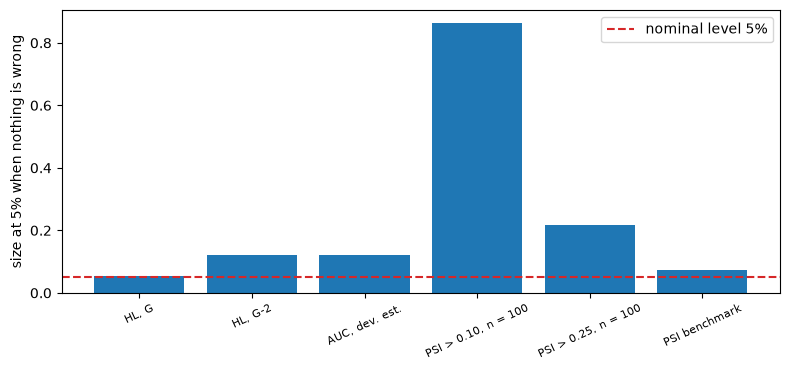

In [8]:
# Exact Jeffreys size at 1%, largest ECB concentration statistic, and the sizes drawn
from riskvalidation.generators.ratings import concentrate
from riskvalidation.harness.exact import rejection_probability
from riskvalidation.validation.rating_system import rating_hhi

jeffreys = rejection_probability("pd.jeffreys", 1000, 0.01, 0.01)["probability"]
initial = np.array(families["concentration"]["outputs"]["generators"]["grades-10-c0.5"]["config"]["initial"])
largest_hhi = max(rating_hhi(concentrate(initial, s), initial).statistic for s in np.linspace(0.0, 1.0, 101))
print("Jeffreys, exact size at 1%:", round(jeffreys, 5))
print("ECB concentration, largest statistic:", round(float(largest_hhi), 4))
print("critical value at 5%:", round(float(stats.norm.isf(0.05)), 4))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(range(len(sizes)), list(sizes.values()), color="tab:blue")
ax.axhline(0.05, color="tab:red", linestyle="--", label="nominal level 5%")
ax.set_xticks(range(len(sizes)))
ax.set_xticklabels(list(sizes), rotation=25, fontsize=8)
ax.set_ylabel("size at 5% when nothing is wrong")
ax.legend()
fig.tight_layout()
plt.show()

The Jeffreys test has an exact size of 0.01383 at the 1% level for 1,000 obligors at a PD of 1%. The concentration statistic peaks at 1.0913 over every redistribution of the ten grades, below the 1.6449 it needs at 5%, so the test cannot reject. The bars put the six sizes of the previous step side by side, and four of them are far above the red line while only the Hosmer-Lemeshow reference with $G$ and the chi-square benchmark are near it. A battery whose members differ so much cannot be read with one threshold.

### Step 7: the register of findings

Each file carries a register of findings, each with a severity (S2 the most serious, S4 the least), a status and the simulation rows that evidence it, plus a few red-team specimens (`F-RED`) that point to generators and not to rows. The next cell counts the findings of the register by severity and status, checks that every evidence row exists, and lists the first six.

In [9]:
# Count the findings of the register by severity and status and check that each names an existing row
keys = {key for n in names for key in rows[n]}
everything = [(n, f) for n in names for f in families[n]["findings"]]
register = [(n, f) for n, f in everything if not f["id"].startswith("F-RED")]
print("findings in the files:", len(everything))
specimens = len(everything) - len(register)
print("red-team specimens:", specimens)
by_severity = Counter(f["severity"] for _, f in register)
by_status = Counter(f["status"] for _, f in register)
print("findings of the register:", len(register), "|", "by severity:", dict(sorted(by_severity.items())))
status_name = {"accepted": "accepted", "closed": "closed", "open": "open"}
print("by status:", {status_name[k]: v for k, v in sorted(by_status.items())})
named = [item.split(":", 1)[-1] for _, f in register for item in f["evidence"]]
print("evidence rows named:", len(named), "| that exist:", sum(1 for key in named if key in keys))
for n, f in register[:6]:
    print(f"{f['severity']} {status_name[f['status']]:9s} {f['id']:20s} {f['title'][LANG][:60]}")

findings in the files: 31
red-team specimens: 8
findings of the register: 23 | by severity: {'S2': 10, 'S3': 7, 'S4': 6}
by status: {'accepted': 17, 'closed': 4, 'open': 2}
evidence rows named: 53 | that exist: 53
S2 closed    F-HL-DOF             Hosmer-Lemeshow with G − 2 degrees of freedom over-rejects o
S3 accepted  F-NORMAL-SIZE        The normal test over five years rejects above its level, as 
S3 accepted  F-TL-TIES            The traffic-lights size depends on the colour of a year with
S3 accepted  F-CHI2-THIN          The chi-square test over grades exceeds its level when a gra
S2 closed    F-AUC-INIT           The ECB AUC test treats the development AUC as known; estima
S4 accepted  F-JEFFREYS-DISCRETE  The Jeffreys test is Bayesian; on a discrete count its exact


The files hold 31 findings, 8 of them red-team specimens, which leaves 23 in the register: 10 of severity S2, 7 of S3 and 6 of S4, with 17 accepted as properties of the tests, 4 closed and 2 open. All 53 evidence rows named exist. The first entries repeat the defects of this notebook, the Hosmer-Lemeshow degrees of freedom, the size of the normal test, the tie rule of the traffic lights and the Jeffreys test on a discrete count. The measurement found defects in the tests it was built to measure, which is the best evidence that it measures something.

## Results

**Answer:** Yes, within a stated reach. The eight families hold 256 simulations and 651,000 repetitions of 42 tests, 537 rates each with its Monte Carlo error, and 47 rows whose simulated rate agrees with an exact probability in all 94 comparisons, with a largest standardised gap of 2.85. Eight rows replay from their seeds to the same rate. The measurement found defects that neither the standard nor the toolkits report: Hosmer-Lemeshow with $G-2$ degrees of freedom rejects a right model 0.1200 of the time, the ECB AUC test 0.1200, the PSI rule above 0.10 fires 0.862 of the time on samples of 100 with nothing changed, the Jeffreys test has an exact size of 0.01383 at 1%, and the concentration statistic peaks at 1.0913, below the 1.6449 it needs.

- **The claim is smaller than "every test under every defect", and it is stated at its true size.** 25 of the 42 tests have a size row and no power row, so the claim covers the size of all of them and the power only of those with a planted defect.
- **Power is mixed, and the mixture is the finding.** In the live measurement the powers run from 0.307 for the portfolio tail backtest to 1.000 for the machine-learning coverage check.
- **The register has 23 findings:** 10 of S2, 7 of S3 and 6 of S4, with 17 accepted, 4 closed and 2 open.

What the claim does not say: that a rate holds outside the generator and the ladder it was measured on, since a ladder is a design choice and power against it is not the probability of detecting a real bank's problem; that any size or power implies a regulatory threshold; or that no other work measures the same things, since "beyond the published literature" is relative to a survey of documentation made in October 2026 (UNVERIFIED beyond what it read).

## Summary

- The claim rests on 256 simulations and 651,000 repetitions of 42 tests, 537 rates each with its Monte Carlo error, 47 rows with an exact probability and 148 generators whose truth is written.
- The live studies of the engine measure size and power for tests of other families, with powers from 0.307 to 1.000.
- All 94 comparisons of a simulated rate with its exact probability agree, and eight rows replay from their seeds.
- The measurement found defects in standard tests, evidenced by the numbers above and by a register of 23 findings.
- Stated at its true size, the claim is the size of every test and the power of those with a planted defect, on the generators and ladders measured.

**What to try next.** Pick another test from the `STUDIES` of `riskvalidation.generators.size_studies`, run its null and its alternative as in step 2 and add it to the figure.

## References

- Morris, T. P., White, I. R. and Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- Brown, L. D., Cai, T. T. and DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised): the conclusion on calibration tests (pages 41 to 42). https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Yurdakul, B. and Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4). https://doi.org/10.21314/JRMV.2020.227
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk. https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Demler, O. V., Pencina, M. J. and D'Agostino, R. B. Sr (2012), Misuse of DeLong test to compare AUCs for nested models, Statistics in Medicine 31(23). https://doi.org/10.1002/sim.5328
- Hosmer, D. W. and Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- The product's research dossiers (CAOS_MANAGE records, `wip/contraste/`): 06 (sections A.3 and D) and 12 (sections 1 to 6); this repository's `docs/design/features/c22-validator/requirements.md` and `tests/test_c22.py`, the requirements and the tests that hold the measurements.